# From deposit and OIS quotes to a discount curve

**Question.** What does today's SOFR market imply about the value of a future
USD payment, and how can we check that a curve query is internally consistent?

We bootstrap the illustrative 24 February 2026 deposit/OIS snapshot, inspect
its discount factors, and reconstruct a forward without calling the forward
API. The study is single-currency and single-curve: no credit spread, FX,
optionality, or liquidity adjustment. An implied forward is a pricing quantity,
not a forecast. [Setup and catalog](../README.md).

The market inputs are observations; `CurveConfiguration` specifies calibration
instruments and conventions. Neither object is itself a curve.


In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import quantsupport as qs
from market_data import load_market

market = load_market()
ref = market.quotes.reference_date
print(
    "Reference date:",
    ref,
)
market.quotes.to_dataframe().head(8)


Reference date: 2026-02-24


,identifier,mid,bid,ask
0,CapletFloorlet_USD_SOFR_3M_10Y_Absolute_0.035_...,0.20,None,None
1,CapletFloorlet_USD_SOFR_3M_10Y_Absolute_0.045_...,0.18,None,None
2,CapletFloorlet_USD_SOFR_3M_10Y_Absolute_0.055_...,0.20,None,None
3,CapletFloorlet_USD_SOFR_3M_12Y_Absolute_0.035_...,0.19,None,None
4,CapletFloorlet_USD_SOFR_3M_12Y_Absolute_0.045_...,0.17,None,None
5,CapletFloorlet_USD_SOFR_3M_12Y_Absolute_0.055_...,0.19,None,None
6,CapletFloorlet_USD_SOFR_3M_1Y_Absolute_0.035_S...,0.33,None,None
7,CapletFloorlet_USD_SOFR_3M_1Y_Absolute_0.045_S...,0.29,None,None


## Configure the bootstrap

The shared loader reads the repository's illustrative SOFR deposit/OIS quotes.
The specification below is the actual configuration, including defaults
resolved by the native library. Its `quotes` list is the linkage to the quote
store. Those strings are market identifiers, not product-constructor boilerplate.

`from_dict` constructs a typed configuration from an in-memory specification;
`from_json` loads the same schema from a file. We reconstruct the loaded spec
here to show where you would supply your own instruments or conventions.

In [2]:
specification = market.curves[0].to_dict()
configuration = qs.CurveConfiguration.from_dict(specification)
specification


{'market_index': 'SOFR',
 'construction': {'type': 'Bootstrapped'},
 'day_counter': 'Actual360',
 'interpolator': 'LogLinear',
 'enable_extrapolation': True,
 'quotes': ['FixedRateDeposit_USD_SOFR_1D',
  'OIS_USD_SOFR_1Y',
  'OIS_USD_SOFR_2Y',
  'OIS_USD_SOFR_3Y',
  'OIS_USD_SOFR_5Y',
  'OIS_USD_SOFR_7Y',
  'OIS_USD_SOFR_10Y',
  'OIS_USD_SOFR_30Y']}

## Construct once and obtain read-only views

Create the context and enter `with context:` to activate request-driven construction. `curve(SOFR)` then retrieves it by index;
`curves()` lists all available curves in a larger setup. A *pillar* is a labelled
bootstrap input; a *node* is a date and discount factor on the resulting curve.
Their tables answer different questions, and pillar labels also identify quote
sensitivities in valuation results.

Use the view inside the context and copy out scalars or tables. On exit the
context clears its constructed market and resets its differentiation tape.
Here we attach no volatility configuration because curve construction does not
need it.

In [3]:
context = qs.PricingContext(
    quotes=market.quotes,
    curves=[configuration],
    csa_policy=market.csa_policy,
)

with context:
    curve = context.curve(qs.MarketIndex.SOFR)
    nodes = curve.nodes()
    pillars = curve.pillars()
    day_counter = curve.day_counter
    start, end = ref + "1Y", ref + "1Y3M"
    df_start, df_end = curve.discount_factor(start), curve.discount_factor(end)
    forward = curve.forward_rate(
        start,
        end,
        qs.Compounding.Simple,
        qs.Frequency.Annual,
    )

print(
    "Curve day count:",
    day_counter,
)
pillars


Curve day count: Actual360


,label,value
0,FixedRateDeposit_USD_SOFR_1D,0.04500
1,OIS_USD_SOFR_1Y,0.04837
2,OIS_USD_SOFR_2Y,0.04528
3,OIS_USD_SOFR_3Y,0.04260
4,OIS_USD_SOFR_5Y,0.04077
5,OIS_USD_SOFR_7Y,0.04033
6,OIS_USD_SOFR_10Y,0.03898
7,OIS_USD_SOFR_30Y,0.03738


## Translate a curve query into a cashflow value

A discount factor converts one unit paid at its maturity into value at the
reference date. With this single USD curve, a deterministic USD 100 payment
has value `100 × discount_factor`. This illustration has no spread, credit risk,
exercise feature, or FX conversion.

A simple forward over an accrual interval follows from the ratio of the two
discount factors. The accrual fraction must use the same day count as the
queried curve. This relation is a useful independent check on convention choices.

In [4]:
accrual = day_counter.year_fraction(
    start,
    end,
)
forward_from_discount_factors = (df_start / df_end - 1) / accrual
pd.Series(
    {
        "interval_start_df": df_start,
        "interval_end_df": df_end,
        "simple_forward_rate": forward,
        "forward_from_discount_factors": forward_from_discount_factors,
        "forward_rate_difference": forward - forward_from_discount_factors,
        "usd_100_at_interval_end_pv": 100 * df_end,
    }
)


interval_start_df                 0.953257
interval_end_df                   0.943517
simple_forward_rate               0.041757
forward_from_discount_factors     0.041757
forward_rate_difference           0.000000
usd_100_at_interval_end_pv       94.351664
dtype: float64

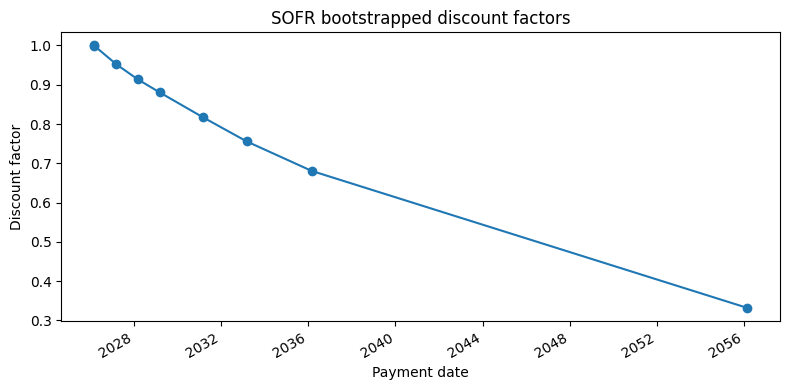

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(
    pd.to_datetime(nodes["date"]),
    nodes["discount_factor"],
    marker="o",
)
ax.set(
    title="SOFR bootstrapped discount factors",
    xlabel="Payment date",
    ylabel="Discount factor",
)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


## Two independent checks and a zero-rate interpretation

For a simple deposit, $P(0,T)=1/(1+q\tau)$; for any future interval,
$F(S,T)=[P(0,S)/P(0,T)-1]/\tau(S,T)$. The first check tests a calibration
input, while the second tests a relationship between constructed values.
The continuously compounded zero rate is $z(T)=-\log P(0,T)/t$.
Do not compare an OIS par quote directly with a zero rate of the same maturity.


In [6]:
import math

assert math.isclose(forward, forward_from_discount_factors, abs_tol=1e-12)
deposit_label = configuration.to_dict()["quotes"][0]
quotes = market.quotes.to_dataframe().set_index("identifier")
deposit_quote = float(quotes.loc[deposit_label, "mid"])
deposit_end = ref + "1D"
deposit_accrual = qs.DayCounter.Actual360.year_fraction(ref, deposit_end)
with context:
    deposit_df = context.curve(qs.MarketIndex.SOFR).discount_factor(deposit_end)
deposit_implied = (1 / deposit_df - 1) / deposit_accrual
assert math.isclose(deposit_implied, deposit_quote, abs_tol=1e-8)
assert nodes["discount_factor"].gt(0).all()

zero_rates = nodes.copy()
zero_rates["time_years"] = zero_rates["date"].map(
    lambda date: day_counter.year_fraction(ref, qs.Date.parse(date))
)
zero_rates = zero_rates.loc[zero_rates["time_years"] > 0].copy()
zero_rates["continuous_zero_rate"] = [
    -math.log(discount) / time
    for discount, time in zip(zero_rates["discount_factor"], zero_rates["time_years"])
]
print(f"One-day deposit repricing residual: {deposit_implied - deposit_quote:.3e}")
print(f"Forward identity residual: {forward - forward_from_discount_factors:.3e}")
print(f"USD 100 due {end} is worth USD {100 * df_end:.4f} today.")
zero_rates[["date", "discount_factor", "continuous_zero_rate"]]


One-day deposit repricing residual: -2.494e-14
Forward identity residual: 0.000e+00
USD 100 due 2027-05-24 is worth USD 94.3517 today.


,date,discount_factor,continuous_zero_rate
1,2026-02-25,0.999875,0.044997
2,2027-03-02,0.952507,0.047215
3,2028-03-01,0.913601,0.044199
4,2029-02-28,0.880772,0.041549
5,2031-02-28,0.817031,0.039753
6,2033-03-02,0.755705,0.039344
7,2036-02-28,0.680452,0.037910
8,2056-03-01,0.331810,0.036226


## Conclusion

This market has positive rates and falling discount factors; that is a property
of this snapshot, not a universal requirement under negative rates. An implied
forward is a pricing rate, not a prediction of the rate that will be realized.
Interpolation conventions affect off-pillar values even when the same quote
instruments are fitted.

Continue with [a swap valuation](../valuation/swaps/tour.ipynb) to use the curve in a
pricer, or [curves and volatility shocks](../volatilitysurface/curves_and_volatility.ipynb)
to inspect a surface and explain changes in swap and caplet value. The
[portfolio-risk example](../sensitivity/portfolio_risk.ipynb) follows these same
quote labels into aggregated risk and a full-revaluation check.